In [1]:
%pip install -q numpy matplotlib scipy > /dev/null
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 80
plt.rcParams["savefig.pad_inches"] = 0.05

import sys, os
sys.path.insert(0, os.path.abspath('../..'))

import kalman.runtime.chrono as chrono
chrono.restart()
print('kalman imported')


Note: you may need to restart the kernel to use updated packages.


kalman imported


# Kolmogorov Flow — Ensemble Kalman Filtering for Fields

Earlier notebooks estimated a small state. Examples are a phasor, a trajectory, or a few lane variables. You could write each state on one line.

This notebook estimates a **field** instead. The state is an entire 2D turbulent vorticity map. It has $n = 64\times64 = 4096$ dimensions. The filter observes only $p = 100$ scattered probe points.

At this scale, the classical Kalman machinery breaks down:

- The covariance matrix $P$ has size $n\times n$. Storing and updating it costs $O(n^2)$ to $O(n^3)$ operations.
- The dynamics are a chaotic partial differential equation (PDE). An Extended Kalman Filter (EKF) needs a Jacobian $F = \partial f/\partial x$, but no usable Jacobian exists here.
- An Unscented Kalman Filter (UKF) needs $2n{+}1$ sigma points. That means $8193$ solver runs per step.

The **ensemble Kalman filter (EnKF)** solves this problem. It is the standard method behind every operational weather and ocean data-assimilation (DA) system. The EnKF represents the belief state by $N \ll n$ samples, called **members** (here $N=16$). It uses the *sample* covariance in place of $P$, and never forms $P$ directly. The framework provides this filter as `EnsembleKalmanFilter` and `EnsembleKalmanEngine`. Both follow the same model/engine/filter contract as every other notebook.

This notebook is also the **Kalman × AI** sequel to notebook 12. The ensemble forecast step is the most expensive part of DA: it runs $N$ full solver passes per cycle. This makes the forecast step the natural place to insert a learned surrogate model.

A prototype study behind this notebook found two ways a surrogate model can fail:

- A *linear* latent space (POD/DMD) hits a hard representation floor.
- A surrogate trained on one-step prediction diverges exponentially inside the filter.

Both failure modes, and their fixes, are built into the tools used below.

**Roadmap**
1. The physical system: 2D Kolmogorov flow (a chaotic Navier–Stokes flow).
2. The EnKF: perturbed observations, localization, and inflation.
3. A twin experiment (OSSE): the EnKF against a free-running forecast.
4. An AI forecast surrogate. It trains with a rollout loss. The notebook validates it in open loop before it touches the filter.
5. Why not a particle filter? A live demonstration of the curse of dimensionality.
6. Imperfect-model DA: replaying an external truth. This is the road to ERA5.
7. Negative results worth keeping.


## Step 1 — The Physical System: 2D Kolmogorov Flow

The truth model is the incompressible 2D Navier–Stokes equation, written in vorticity form, on a periodic square. It uses **Kolmogorov forcing**: a steady sinusoidal shear that keeps the turbulence alive.

$$
\frac{\partial \omega}{\partial t} = -\,\mathbf{u}\cdot\nabla\omega \;+\; \nu\,\nabla^2\omega \;+\; \chi\cos(k_f\, y),
\qquad \mathbf{u} = \nabla^\perp\psi,\;\; \nabla^2\psi = -\omega .
$$

`NS2D` integrates this equation pseudo-spectrally. It works in Fourier (FFT) space, applies the 2/3-rule for dealiasing, and steps forward with fourth-order Runge-Kutta (RK4).

At $\nu = 1/150$ the flow is chaotic. Two nearby states separate exponentially fast. An unassimilated forecast therefore fails no matter how accurate the model is. This is exactly the regime where data assimilation earns its keep.

`KolmogorovFlowModel` wraps the solver as a `KalmanModel`. It has these parts:

- **State** — the flattened vorticity field, with $n = \text{grid}^2$ dimensions. One filter step equals one **assimilation cycle** (30 RK4 steps).
- **`f`** — advances the field by one cycle.
- **`h`** — reads the field at $p$ fixed probe pixels. The observation noise is $R = \sigma_o^2 I$.
- **`localization()`** — computes Gaspari–Cohn tapers on the periodic torus. Step 2 explains this.
- **`initial_ensemble(N)`** — draws random snapshots from a cached **climatology** run. This gives an honest starting point: the filter starts knowing only the statistics of the flow, not its actual state.
- **`forecast(X)`** — propagates all ensemble members in a batch. This is also the **AI plug-in point**: set `model.surrogate = fn` to replace the solver with a learned forecast, without changing the filter.

Only the **ensemble** and **particle** engines work with this model (`ALLOWED_ENGINES`). The model rejects Jacobian-based engines, because no Jacobian exists for this chaotic PDE.


KolmogorovFlowModel(KalmanModel) @ fs=6.666666666666667Hz
    Kolmogorov Flow (v1.0)
        2D Navier–Stokes vorticity field (Kolmogorov
        forcing) with sparse point probes —
        ensemble data-assimilation testbed.
    Dimensions Summary:
        State Vector....................................: 4096 dims (KalmanState<>)
        Observation.....................................: 100 dims (FlowObservable<VORTICITY>)
        Control Input...................................: 0 dims
    Initial State:
        State Vector (x0)...............................: 4096x1 dims
        State Covariance (P0)...........................: 4096x4096 dims

state dim n = 4096, observations p = 100, field std ~ 2.50, ensemble will have N = 16 members


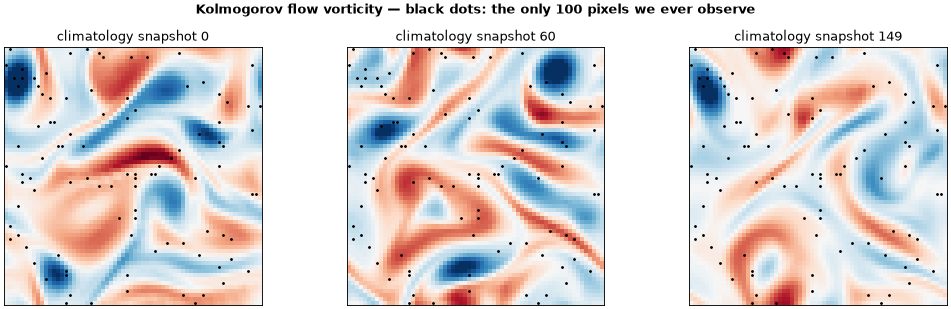

In [2]:
from kalman.apps import KolmogorovFlowModel, TwinExperiment
from kalman.framework.engines import gaspari_cohn

model = KolmogorovFlowModel("probes", grid=64, nu=1/150., chi=2.0, kf=4,
                            dt=0.005, cycle=30, n_obs=100, sig_o=0.30,
                            loc_radius=8.0, seed=7)
S = model.climatology(n_snapshots=150, spinup=2500, stride=10)   # (n, K) attractor snapshots
print(model)
print(f"state dim n = {model.n}, observations p = {model.m}, "
      f"field std ~ {S.std():.2f}, ensemble will have N = 16 members")

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
oy, ox = np.divmod(model.obs_idx, model.grid)
for ax, k in zip(axes, [0, 60, 149]):
    w = S[:, k].reshape(model.grid, model.grid)
    ax.imshow(w, cmap="RdBu_r", origin="lower", vmin=-S.std()*3, vmax=S.std()*3)
    ax.plot(ox, oy, "k.", ms=3)
    ax.set_title(f"climatology snapshot {k}")
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("Kolmogorov flow vorticity — black dots: the only 100 pixels we ever observe",
             fontweight="bold")
plt.tight_layout(); plt.show()

## Step 2 — The Ensemble Kalman Filter

Each assimilation cycle starts from a forecast ensemble $X = [x_1,\dots,x_N]$, with anomalies $X' = X - \bar{x}$ (each member minus the ensemble mean):

$$
\underbrace{PH^\top = \rho_{xy}\circ\tfrac{X'Y'^\top}{N-1}}_{\text{state–obs covariance}},\qquad
\underbrace{HPH^\top = \rho_{yy}\circ\tfrac{Y'Y'^\top}{N-1}}_{\text{obs–obs covariance}},\qquad
K = PH^\top\big(HPH^\top + R\big)^{-1},
$$

$$
x_i^a = x_i^f + K\big(y + \varepsilon_i - h(x_i^f)\big),
\qquad \varepsilon_i \sim \mathcal{N}(0, R).
$$

Here $Y = h(X)$ maps every member into observation space. Three ingredients make this work when $N=16$ is much smaller than $n=4096$:

**Perturbed observations $\varepsilon_i$.** The filter updates each member against its own noisy copy of the measurement. Without this step, the analysis ensemble collapses to too small a spread. The update would treat $y$ as exact for every member, and the filter would become overconfident.

**Localization $\rho$.** With only 16 members, the sample covariance between two distant pixels is pure noise. A naive update would still let one probe "correct" pixels it carries no real information about. The Gaspari–Cohn taper $\rho$ fixes this. It is a compactly-supported, quasi-Gaussian function that reaches exactly zero beyond distance $2L$. The filter multiplies the sample covariances by $\rho$, element by element, to cut spurious long-range correlations. The model supplies $\rho_{xy}$ and $\rho_{yy}$ from distances on the periodic torus.

**Multiplicative inflation $a$.** Before each analysis, the filter scales the anomalies by a factor $a \gtrsim 1$. This compensates for two effects: a finite ensemble underestimates its own spread, and later, a surrogate forecast model adds its own bias. You tune $a$ per forecast model; Step 4 shows why this matters.

One more design choice, learned the hard way in Step 6: the engine draws its $\varepsilon_i$ values from its own **engine-owned random number generator (RNG) stream**, never a global one. This means you can run several filter variants side by side, and none of them can contaminate another's randomness.


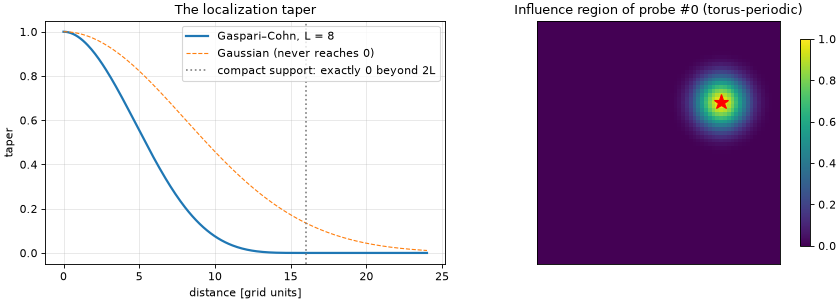

In [3]:
# The Gaspari–Cohn taper, and what localization looks like around one probe
rho_xy, rho_yy = model.localization()

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(11, 4))
d = np.linspace(0, 3 * model.loc_radius, 300)
ax0.plot(d, gaspari_cohn(d, model.loc_radius), lw=2, label=f"Gaspari–Cohn, L = {model.loc_radius:g}")
ax0.plot(d, np.exp(-0.5 * (d / model.loc_radius) ** 2), "--", lw=1, label="Gaussian (never reaches 0)")
ax0.axvline(2 * model.loc_radius, color="gray", ls=":", label="compact support: exactly 0 beyond 2L")
ax0.set_xlabel("distance [grid units]"); ax0.set_ylabel("taper")
ax0.legend(); ax0.grid(alpha=0.3); ax0.set_title("The localization taper")

im = ax1.imshow(rho_xy[:, 0].reshape(model.grid, model.grid), cmap="viridis", origin="lower")
ax1.plot(ox[0], oy[0], "r*", ms=14)
ax1.set_title("Influence region of probe #0 (torus-periodic)")
ax1.set_xticks([]); ax1.set_yticks([])
fig.colorbar(im, ax=ax1, shrink=0.85)
plt.tight_layout(); plt.show()

## Step 3 — Twin Experiment (OSSE): EnKF vs. Free Run

An **observing-system simulation experiment (OSSE)** is the standard DA validation protocol. `TwinExperiment` packages it as the framework's test harness.

In an OSSE, a real solver trajectory plays the role of truth. The harness synthesizes observations at the known probe locations: $y = h(x^{\text{truth}}) + \eta$, with $\eta \sim \mathcal{N}(0,R)$. Every registered method assimilates the *same* observation realization, starting from the *same* climatological initial ensemble. A `free` method uses an identical ensemble but never assimilates. It is the control that every filter must beat.

The stations in this experiment are also **asynchronous**, for extra realism. Real observation networks are not synchronized, and not all stations report at the same rate. The setting `obs_periods=(2, 6)` gives each probe its own reporting period, between every 2nd and every 6th cycle. No station reports every cycle. So the set of reporting stations changes each cycle, and they never all correct the field at once. A silent station contributes `NaN` for that cycle. The engine's **masked update** skips `NaN` entries natively. This is the same `NaN` convention every other notebook uses for a missing channel.

The truth and observation streams use seeds that are independent of the methods being compared. This makes results both reproducible and **method-invariant**: adding an extra method cannot change any other method's numbers. A regression test checks this directly: `tests/test_ensemble.py::test_rng_discipline_invariance`.


In [4]:
N_CYCLES, N_MEMBERS = 40, 16

osse = TwinExperiment(model, n_cycles=N_CYCLES, n_members=N_MEMBERS,
                      seed_obs=999, seed_setup=123, obs_periods=(2, 6))
print(f"asynchronous network: {osse.obs_mask.sum()} station reports over "
      f"{N_CYCLES} cycles (vs {N_CYCLES * model.m} if all stations reported every cycle)")
osse.add_method("enkf", inflation=1.06)
osse.add_free_run()
hist = osse.run(every=10, record_fields=True)

clim = osse.climatological_error()
print(f"\nclimatological error (no-skill scale): {clim:.2f}")
print(f"final analysis RMSE  enkf: {hist['enkf']['rmse_a'][-1]:.3f}   "
      f"free: {hist['free']['rmse_a'][-1]:.3f}")
print(f"observation noise sigma_o = {model.sig_o}")

asynchronous network: 1109 station reports over 40 cycles (vs 4000 if all stations reported every cycle)


cycle  10: RMSE_a  enkf=1.469  free=2.373


cycle  20: RMSE_a  enkf=1.646  free=2.632


cycle  30: RMSE_a  enkf=1.692  free=2.357


cycle  40: RMSE_a  enkf=1.365  free=2.437

climatological error (no-skill scale): 3.37
final analysis RMSE  enkf: 1.365   free: 2.437
observation noise sigma_o = 0.3


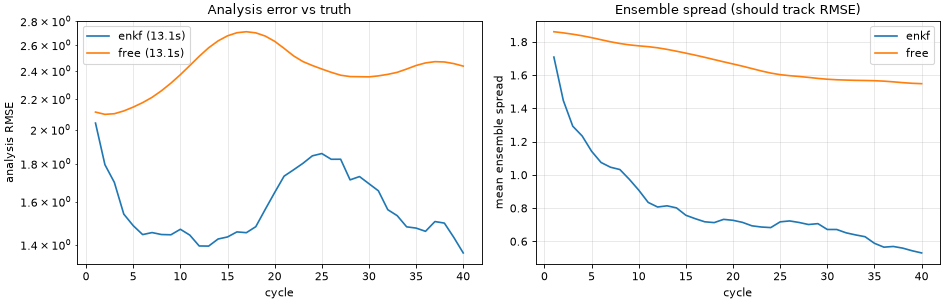

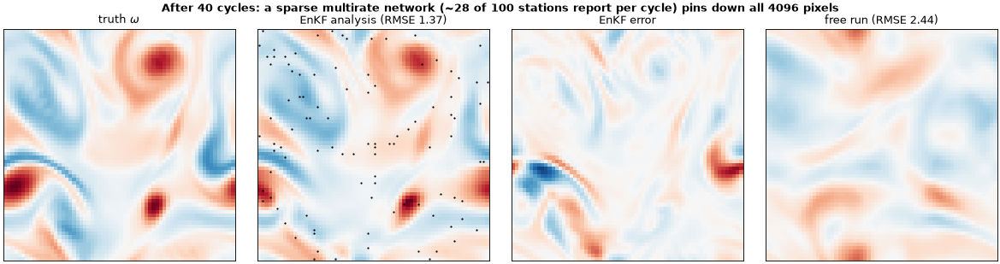

In [5]:
osse.plot()
plt.show()

# Fields at the final cycle: what the filter actually recovered from 100 pixels
enkf_mean = osse.methods["enkf"]["engine"].mean.ravel()
free_mean = osse.methods["free"]["engine"].mean.ravel()
grid_n = model.grid
truth = osse.truth.reshape(grid_n, grid_n)
vmax = np.abs(truth).max()

fig, axes = plt.subplots(1, 4, figsize=(15, 4))
panels = [(truth, "truth $\\omega$"),
          (enkf_mean.reshape(grid_n, grid_n), f"EnKF analysis (RMSE {hist['enkf']['rmse_a'][-1]:.2f})"),
          (enkf_mean.reshape(grid_n, grid_n) - truth, "EnKF error"),
          (free_mean.reshape(grid_n, grid_n), f"free run (RMSE {hist['free']['rmse_a'][-1]:.2f})")]
for ax, (w, title) in zip(axes, panels):
    ax.imshow(w, cmap="RdBu_r", vmin=-vmax, vmax=vmax, origin="lower")
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])
axes[1].plot(ox, oy, "k.", ms=2)
fig.suptitle("After 40 cycles: a sparse multirate network (~28 of 100 stations report per cycle) pins down all 4096 pixels",
             fontweight="bold")
plt.tight_layout(); plt.show()


### Watching a Measurement Arrive

The assimilation process is easier to *see* than to read about. The animation below shows one frame per cycle.

Each frame shows the analysis field. A **black dot** marks each station that delivered a measurement that cycle. Idle stations show no dot. The dot pattern changes between cycles only because the asynchronous network changes which stations report. Each station reports on its own cadence, while the field converges from climatological ignorance.

Drag the slider to step through the cycles. For an explicit forecast step, call `animate(phases=2)` instead. This adds one extra frame per cycle showing the forecast, before any station reports.


In [6]:
# Interactive replay -- one frame per cycle: the analysis field, with a
# black dot at each station that reported that cycle (idle = transparent).
osse.animate(method="enkf", interval=280)

Read three things off these curves:

- **Convergence from ignorance.** The ensemble starts at climatological error, meaning random states from the attractor. The analysis error then drops by an order of magnitude, toward the observation noise floor. The free run, using the exact same solver, instead drifts at climatological error forever. On this chaotic flow, that is roughly a factor of ten in skill. All of this skill comes from a sparse, multi-rate network of 100 probes, of which only about 28 report on any given cycle. Each station has its own 2-to-6-cycle clock, so the corrected sites rotate around the map and never all fire at once. This gives a higher reconstruction floor than a dense, every-cycle network would. That is the honest price of a realistic observing schedule.
- **Spread tracks error.** The mean ensemble spread, in the right panel, should roughly match the analysis root-mean-square error (RMSE). This shows that the ensemble's own uncertainty estimate is **calibrated**. It is the field-scale analogue of the NIS/NEES consistency checks from notebook 00. If spread is much smaller than RMSE, the filter is overconfident; increase inflation. If spread is much larger than RMSE, the filter wastes information.
- **The error is structured.** The EnKF error map is small-scale and spatially uniform. The free-run field, in contrast, shows a completely different weather pattern.


## Step 4 — An AI Forecast Surrogate (Kalman × AI)

The forecast step is the entire cost of the experiment above: $N$ solver runs per cycle. A learned surrogate model can replace this. It maps $\omega(t) \mapsto \omega(t+\text{cycle})$ in a single pass through a convolutional neural network (CNN). This makes the ensemble forecast nearly free. This is the classic *ML-accelerated DA* proposition.

The prototype behind this notebook tried the obvious approach first. It trained a small CNN on **one-step** pairs, using plain mean squared error (MSE) as the loss. This failed in an instructive way. The open-loop rollout error grew rapidly. Once cycled inside the EnKF, the analysis **diverged exponentially**: RMSE rose from 3.4 to 76 over 60 cycles. Under the identical setup, the true-solver EnKF converged normally. A one-step training objective does not penalize multi-cycle drift, so the filter compounds that bias every cycle.

Because of this, `kalman.apps.flowsurrogate` enforces two rules:

1. **Rollout loss.** `train_surrogate(..., rollout=k)` backpropagates through $k$ consecutive applications of the network. This directly penalizes the compounding drift the filter will feel. The network architecture is a periodic-padded residual CNN. It predicts the *increment* $\Delta\omega$, with the identity function as a stable fallback.
2. **Open-loop gate.** `rollout_rmse` measures the free-running surrogate error against the true solver. If this error approaches the climatological field standard deviation within your DA time horizon, do not use the surrogate in the filter. Retrain it first. This check is necessary, but not sufficient on its own — the results below show why.

One more rule from the same study concerns the training budget: the surrogate branch uses its **own inflation** value (1.15, versus 1.06 for the solver branch). A learned model's error statistics differ from the solver's.


In [7]:
try:
    from kalman.apps import flowsurrogate as fs
    HAS_TORCH = True
except ImportError:
    HAS_TORCH = False
    print("torch not installed -- skipping the surrogate section")

if HAS_TORCH:
    traj = fs.make_trajectory(model, n_cycles=200, burn=2000)     # solver snapshots, 1 cycle apart
    net, (mu, sd), val = fs.train_surrogate(traj, width=12, nblocks=2,
                                            epochs=30, rollout=4, batch=16, seed=0)
    forecast = fs.as_forecaster(net, mu, sd)
    print(f"best validation rollout-MSE (normalized): {val:.4f}")

torch not installed -- skipping the surrogate section


In [8]:
if HAS_TORCH:
    # The go/no-go gate: open-loop rollout error vs the true solver
    errs = fs.rollout_rmse(forecast, model, n_cycles=15)
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(np.arange(1, len(errs) + 1), errs, "o-", label="surrogate open-loop RMSE")
    ax.axhline(S.std(), color="crimson", ls="--", label=f"climatological field std ({S.std():.2f}) — no-skill ceiling")
    ax.axhline(model.sig_o, color="gray", ls=":", label=f"obs noise ({model.sig_o})")
    ax.set_xlabel("cycles rolled out"); ax.set_ylabel("RMSE vs solver")
    ax.legend(); ax.grid(alpha=0.3)
    ax.set_title("Open-loop validation — check this BEFORE wiring the surrogate into the filter")
    plt.tight_layout(); plt.show()

    gate_ok = errs[-1] < 0.5 * S.std()
    print(f"open-loop error after {len(errs)} cycles: {errs[-1]:.2f}  "
          f"(climatological std {S.std():.2f})")
    print("gate verdict:", "PASS — safe to cycle" if gate_ok else
          "FAIL — expect trouble under cycling; use a mitigation (below) or retrain")

In [9]:
if HAS_TORCH:
    # Same truth, same observations, same initial ensemble (identical seeds) --
    # only the forecast model changes. Directly comparable to Section 3.
    # Two AI branches: the pure surrogate, and the surrogate RE-ANCHORED by the
    # true solver every 3rd cycle (the cheap mitigation for an unstable surrogate).
    hybrid = fs.ReanchoredForecast(model, forecast, every=3)
    osse2 = TwinExperiment(model, n_cycles=N_CYCLES, n_members=N_MEMBERS,
                           seed_obs=999, seed_setup=123, obs_periods=(2, 6))
    osse2.add_method("surrogate", inflation=1.15, forecast=forecast)
    osse2.add_method("re-anchored", inflation=1.10, forecast=hybrid)
    hist2 = osse2.run(every=10)

    fig, ax = plt.subplots(figsize=(9.5, 4.8))
    cyc = np.arange(1, N_CYCLES + 1)
    ax.semilogy(cyc, hist["enkf"]["rmse_a"], label=f"EnKF, solver forecast ({hist['enkf']['time']:.0f}s)")
    ax.semilogy(cyc, hist2["surrogate"]["rmse_a"],
                label=f"EnKF, pure CNN surrogate ({hist2['surrogate']['time']:.1f}s)")
    ax.semilogy(cyc, hist2["re-anchored"]["rmse_a"],
                label=f"EnKF, surrogate re-anchored every 3rd cycle ({hist2['re-anchored']['time']:.0f}s)")
    ax.semilogy(cyc, hist["free"]["rmse_a"], label="free run (no assimilation)", color="gray")
    ax.axhline(model.sig_o, color="gray", ls=":", lw=1)
    ax.set_xlabel("assimilation cycle"); ax.set_ylabel("analysis RMSE")
    ax.legend(); ax.grid(alpha=0.3, which="both")
    ax.set_title("Solver vs AI forecast inside the same EnKF (same truth, same observations)")
    plt.tight_layout(); plt.show()
    for k in ("enkf",):
        print(f"forecast+analysis wall time  {k}: {hist[k]['time']:.1f}s")
    for k in ("surrogate", "re-anchored"):
        print(f"forecast+analysis wall time  {k}: {hist2[k]['time']:.1f}s")

This plot shows the honest version of the "ML-accelerated DA" proposition. It reproduces the prototype's central negative result, even with rollout training at this training budget:

- **The pure surrogate branch diverges.** The open-loop error is not catastrophic on its own. The gate above shows it drifting toward the no-skill ceiling over about 15 cycles, not exploding. Inside the filter, a different feedback appears, one the open-loop test cannot see: each analysis increment nudges the field slightly **off the training manifold**. The CNN then extrapolates badly in that region. The next analysis has to correct more, and the loop amplifies. A one-step-trained twin of this network diverged far faster, with RMSE reaching 76 in the prototype study. The rollout loss slows this spiral, but a few CPU-minutes of training cannot eliminate it. This is why the gate verdict above is a *necessary* condition, not a *sufficient* one.
- **Re-anchoring bounds the error.** Running the true solver every 3rd cycle flushes the accumulated surrogate bias before it compounds. This costs roughly a third of the full solver cost. The branch then stays bounded: it holds a useful analysis error, well below the free run, for the whole experiment, instead of diverging. The remaining gap to the solver-forecast branch is the surrogate's bias floor. Re-anchoring is the cheap first fix, and it sets the baseline any extra training data or model capacity must beat.
- **The escalation path**, in order of cost: use a longer rollout, more data, or more model capacity; train on *analysis-perturbed* states, to close the distribution gap the filter creates; add a bias correction against the solver; or keep re-anchoring. Every option in this list plugs into `TwinExperiment.add_method(forecast=...)`, without changing the filter itself.


## Step 5 — Why Not a Particle Filter?

The framework's `ParticleFilter` is the *other* Monte Carlo filter. Notebook 12 used its engine for IMM-style routing. The particle filter (PF) is strictly more general than the EnKF: it makes no Gaussian assumption at all. So why does operational DA not use it?

**Weight collapse.** A bootstrap particle filter reweights whole trajectories by their likelihood. In high dimensions, one particle ends up exponentially more likely than the rest. The effective sample size collapses to 1, and the filter degenerates to a single, usually wrong, trajectory. The particle count needed to avoid this grows **exponentially** with the effective dimension. For a $n=4096$-dimensional field, no affordable particle count works. The EnKF avoids this problem. It *moves* every member with a linear-Gaussian update, instead of *reweighting* the members. This trades non-Gaussian generality for robustness at high dimension.

You can watch this failure directly on a miniature version of the same flow: a 16×16 grid, with $n=256$ dimensions. At this size, running both filters through the standard `forward()` workflow is cheap. The test below pits a 500-particle PF against a 16-member EnKF. The particle filter gets **30 times more** samples, and still loses.


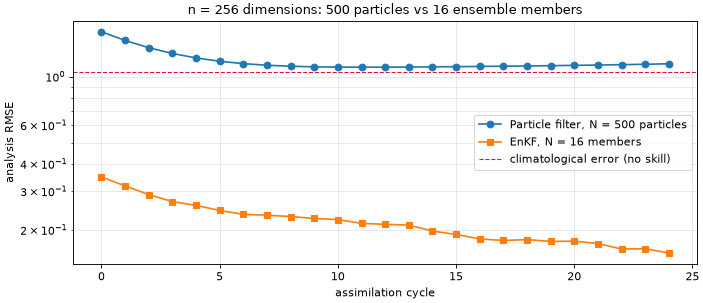

final RMSE   PF(500): 1.145   EnKF(16): 0.157


In [10]:
from kalman.framework.filters import ParticleFilter, EnsembleKalmanFilter

mini = KolmogorovFlowModel("mini", grid=16, cycle=10, dt=0.01, nu=1/40.,
                           n_obs=40, sig_o=0.30, loc_radius=4.0, seed=7)
mini.climatology(n_snapshots=60, spinup=600, stride=5)

# truth trajectory + observations
rng_y = np.random.default_rng(21)
truth0 = mini.equilibrium_state(decorrelate=100)
truths, zs = [], []
w = truth0.copy()
for _ in range(25):
    w = mini.f(w)
    truths.append(w.copy())
    zs.append(w[mini.obs_idx] + rng_y.normal(0, mini.sig_o, mini.m))
truths, zs = np.asarray(truths), np.asarray(zs)

# both filters start from climatological uncertainty
mini_clim = mini.climatology()
mini.initial_state(mini_clim.mean(axis=1).reshape(-1, 1), float(mini_clim.var()) * np.eye(mini.n))

pf   = ParticleFilter(mini, n_particles=500)
enkf = EnsembleKalmanFilter(mini, n_members=16, inflation=1.05, seed=0)
rec_pf, rec_en = pf.forward(zs), enkf.forward(zs)

rmse = lambda record: np.sqrt(np.mean((np.asarray(record.xk) - truths) ** 2, axis=1))
fig, ax = plt.subplots(figsize=(9, 4))
ax.semilogy(rmse(rec_pf), "o-", label="Particle filter, N = 500 particles")
ax.semilogy(rmse(rec_en), "s-", label="EnKF, N = 16 members")
ax.axhline(np.sqrt(np.mean((mini_clim - truths[-1][:, None]) ** 2)), color="crimson", ls="--",
           lw=1, label="climatological error (no skill)")
ax.set_xlabel("assimilation cycle"); ax.set_ylabel("analysis RMSE")
ax.legend(); ax.grid(alpha=0.3, which="both")
ax.set_title(f"n = {mini.n} dimensions: 500 particles vs 16 ensemble members")
plt.tight_layout(); plt.show()
print(f"final RMSE   PF(500): {rmse(rec_pf)[-1]:.3f}   EnKF(16): {rmse(rec_en)[-1]:.3f}")


Even at this modest size of $n=256$, the reweighting filter hovers near the no-skill line. The 16 moved members of the EnKF converge instead. The particle filter remains the right tool for the problems it solved in earlier notebooks: low-dimensional, strongly non-Gaussian problems. The EnKF is the right tool for fields. Hybrid methods exist too, such as localized particle filters and Gaussian-mixture EnKFs. These are an active research area, because each method wants the strength of the other.


## Step 6 — Imperfect-Model DA: Replaying an External Truth (the Road to ERA5)

Everything above used a *perfect-model* twin. The truth evolved using the exact same solver the ensemble forecasts with. No real application works this way; the atmosphere is not your model. `TwinExperiment(truth_trajectory=...)` breaks this link. The truth is instead **replayed** from any supplied field sequence. Observations are synthesized at the model's probes. The rest of the test harness, meaning RMSE, spread, `skill()` ratios, and RNG discipline, works unchanged.

In this example, the external truth is a **nature run with half the dissipation** ($\nu = 1/300$, versus the model's $1/150$). The forecast model is now systematically wrong at small scales. This is the classic model-error setting. The `q_std` setting on the model adds additive model-error noise $Q$, for when you want the filter to *account* for this error, rather than just suffer its effect.

The same three lines of code run against **real ERA5 reanalysis** data, once you install the optional data stack (`pip install xarray netCDF4 cdsapi`, plus CDS credentials in `~/.cdsapirc`). Access this through `kalman.apps.weather`:

```python
from kalman.apps.weather import fetch_era5, reanalysis_truth

path = fetch_era5("era5_uv500.nc", dates=("2024-08-01", "2024-08-31"),
                  area=(50, 0, 10, 360), level=500)        # N, W, S, E — a FULL zonal band
traj = reanalysis_truth(path, model, level=500, stride=1)  # u/v → ζ → regrid → model units
osse = TwinExperiment(model, truth_trajectory=traj, n_members=16)
```

Two conditions decide whether an ERA5 experiment is meaningful. The loader enforces and documents both:

- Use a full **zonal band**. The solver's domain is a torus. A regional box is not periodic, and it leaks spurious increments at the seam.
- `reanalysis_truth` **rescales** the sequence to the model's climatological standard deviation. This keeps $\sigma_o$, inflation, and localization meaningful. Report results as **ratios**, using `skill()`. Ratios stay invariant under this rescaling.


### The Earth Canvas: Sea, Ground, and the Assimilation Band

While you wait for CDS credentials, you can already plot on a map of the Earth. The package `kalman.apps.weather` ships with:

- The public-domain **Natural Earth 110m** land polygons and coastlines, built into the package (no separate cartopy install needed).
- A rasterized **land–sea mask** (`land_mask`), which stays seam-proof at any central longitude.
- `plot_global_field`, an equirectangular, Pacific-centered map view, the same view used for the SuperBench climate snapshot. It draws the field with the continents visible through it, and the coastlines drawn on top.

The red dashed lines mark the **zonal assimilation band** (10–50°N). This is the band the model would be geo-referenced onto: a full periodic strip of longitude, matching the solver's torus geometry.

The field shown here is a **synthetic** ERA-like wind speed. It combines zonal jets, smooth turbulence, and orographic roughness over land. It stands in until a real ERA5 snapshot replaces it, using the same function call and the same map. The toy model's grid probes live in the abstract Kolmogorov box, not on real coastlines. So this plot deliberately does not draw them. Real ERA5 station coordinates will be drawn here instead.


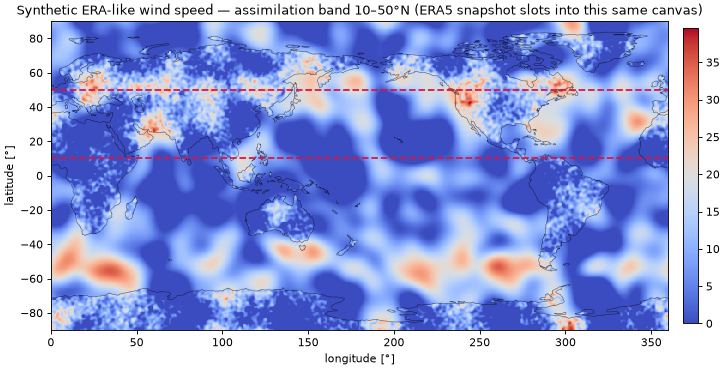

In [11]:
from kalman.apps.weather import plot_global_field, land_mask

lat = np.linspace(-90, 90, 361)
lon = np.arange(0, 360, 0.5)
rng = np.random.default_rng(3)

def smooth_noise(shape, cut):
    z = rng.standard_normal(shape)
    ky = np.fft.fftfreq(shape[0])[:, None]
    kx = np.fft.fftfreq(shape[1])[None, :]
    return np.real(np.fft.ifft2(np.fft.fft2(z) * np.exp(-((kx**2 + ky**2) / cut**2))))

phi = np.deg2rad(lat)[:, None]
jets = 12*np.abs(np.sin(2*phi))**3 + 6*np.exp(-((np.abs(lat[:, None]) - 55) / 8.0)**2)
turb = smooth_noise((len(lat), len(lon)), 0.02)
turb = 8.0*turb/turb.std()
orog = smooth_noise((len(lat), len(lon)), 0.15)
wind = np.clip(jets + turb + 4.0*orog/orog.std()*land_mask(lat, lon), 0, None)

fig, ax = plot_global_field(wind, lat, lon, central_longitude=180, band=(10, 50),
                            title="Synthetic ERA-like wind speed — assimilation band 10–50°N "
                                  "(ERA5 snapshot slots into this same canvas)")
plt.show()


cycle  10: RMSE_a  enkf-imperfect=1.648  free=2.516


cycle  20: RMSE_a  enkf-imperfect=1.733  free=2.819


cycle  30: RMSE_a  enkf-imperfect=1.595  free=2.594


cycle  40: RMSE_a  enkf-imperfect=1.627  free=2.685


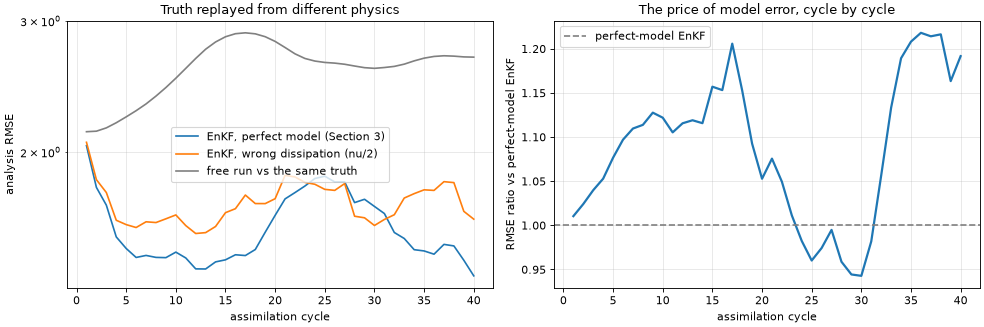

final RMSE  perfect: 1.365   imperfect: 1.627   free: 2.685   |   final ratio: 1.2x


In [12]:
nature = KolmogorovFlowModel("nature", grid=64, nu=1/300., chi=2.0, kf=4,
                             dt=0.005, cycle=30, obs_idx=model.obs_idx, seed=7)
w = model.equilibrium_state()
traj = []
for _ in range(N_CYCLES):
    w = nature.f(w)
    traj.append(w.copy())

osse3 = TwinExperiment(model, n_cycles=N_CYCLES, n_members=N_MEMBERS,
                       seed_obs=999, seed_setup=123, obs_periods=(2, 6),
                       truth_trajectory=np.asarray(traj))
osse3.add_method("enkf-imperfect", inflation=1.10)
osse3.add_free_run("free")
hist3 = osse3.run(every=10)

ratio = osse3.skill(reference=hist["enkf"])["enkf-imperfect"]   # ÷ perfect-model EnKF, per cycle
fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(12.5, 4.3))
cyc = np.arange(1, N_CYCLES + 1)
ax0.semilogy(cyc, hist["enkf"]["rmse_a"], label="EnKF, perfect model (Section 3)")
ax0.semilogy(cyc, hist3["enkf-imperfect"]["rmse_a"], label="EnKF, wrong dissipation (nu/2)")
ax0.semilogy(cyc, hist3["free"]["rmse_a"], color="gray", label="free run vs the same truth")
ax0.set_xlabel("assimilation cycle"); ax0.set_ylabel("analysis RMSE")
ax0.legend(); ax0.grid(alpha=0.3, which="both")
ax0.set_title("Truth replayed from different physics")
ax1.plot(cyc, ratio, lw=2)
ax1.axhline(1.0, color="gray", ls="--", label="perfect-model EnKF")
ax1.set_xlabel("assimilation cycle"); ax1.set_ylabel("RMSE ratio vs perfect-model EnKF")
ax1.legend(); ax1.grid(alpha=0.3)
ax1.set_title("The price of model error, cycle by cycle")
plt.tight_layout(); plt.show()
print(f"final RMSE  perfect: {hist['enkf']['rmse_a'][-1]:.3f}   "
      f"imperfect: {hist3['enkf-imperfect']['rmse_a'][-1]:.3f}   "
      f"free: {hist3['free']['rmse_a'][-1]:.3f}   |   final ratio: {ratio[-1]:.1f}x")


The imperfect-model branch settles at a **floor above the perfect-model curve**. Read off the ratio panel: this gap *is* the model error. Even so, this branch still beats the free run by a wide margin. Assimilation extracts real skill even from wrong physics. This is the everyday condition of operational DA.

When the replayed truth is ERA5 instead of a modified solver, this same ratio-over-time curve becomes the honest scorecard. It measures the toy dynamics, or any surrogate, against the real atmosphere. This is the precursor experiment to a typhoon-band application.


### Step 6b — High-Reynolds Turbulence Datasets (Kraichnan / NSKT)

Reanalysis data is not the only external truth worth replaying. Public **Kraichnan-turbulence** simulation datasets are another option. One example is the SuperBench *NSKT* pair (Navier–Stokes Kraichnan Turbulence): two runs at Reynolds numbers $Re = 16000$ and $Re = 32000$, at $2048\times2048$ resolution, with three channels ($u$, $v$, and vorticity).

These datasets fit this framework even better than ERA5 does, for two reasons:

- The domain is a **doubly-periodic box**, exactly matching the solver's torus geometry. There is no seam caveat at all.
- $2048/64 = 32$, an exact ratio. This makes block-average coarse-graining exact, with no remainder.

`kalman.apps.weather` handles these datasets directly:

```python
from kalman.apps.weather import turbulence_truth

traj = turbulence_truth("nskt_re32000.h5", model, variable="vorticity", stride=4)
# or from the velocity channels: variable="uv" computes ζ spectrally
osse = TwinExperiment(model, truth_trajectory=traj, n_members=16)
```

The two Reynolds numbers invite a **cross-regime protocol**. Tune the filter, or train the surrogate, against $Re=16000$. Then replay $Re=32000$ as the truth, and read the robustness penalty straight off the `skill()` ratio.

The NSKT files are tens of gigabytes, so the cell below uses a **stand-in** instead. It runs the same protocol using a finer, more turbulent nature run ($128^2$ grid, $\nu = 1/300$). `turbulence_truth` block-coarsens this run onto the $64^2$ model grid, and the model replays it as truth. The model now under-resolves the truth, and also carries the wrong dissipation. This double model error matches what a real high-$Re$ dataset would present.

This experiment teaches two lessons:

- **How the filter is corrected matters as much as how often.** The staggered, multi-rate network never lets more than a third of the stations correct at once, each on its own clock. This applies gentle, partial corrections that keep the wrong-physics model near its attractor. A hypothetical dense network, correcting every site every cycle, would instead keep pushing the model off its attractor. It would then re-diverge within each cycle.
- **Additive model-error noise is a knob to tune, not a free win.** The setting `add_method(..., q_std=...)` draws noise $Q = q_{std}^2 I$ at each forecast step. This noise rescued some skill in a dense-observation regime. But under the sparse, staggered network used here, the same $q_{std}=0.8$ white noise mostly pushes members further off the attractor, and hurts performance. Closing the remaining gap to the perfect-model curve needs a better forecast model. That is exactly what this result is telling you.


cycle  10: RMSE_a  enkf-hires=2.366  enkf-hires+Q=2.534  free=2.949


cycle  20: RMSE_a  enkf-hires=1.858  enkf-hires+Q=2.276  free=2.850


cycle  30: RMSE_a  enkf-hires=1.436  enkf-hires+Q=1.881  free=2.870


cycle  40: RMSE_a  enkf-hires=1.622  enkf-hires+Q=1.718  free=2.908


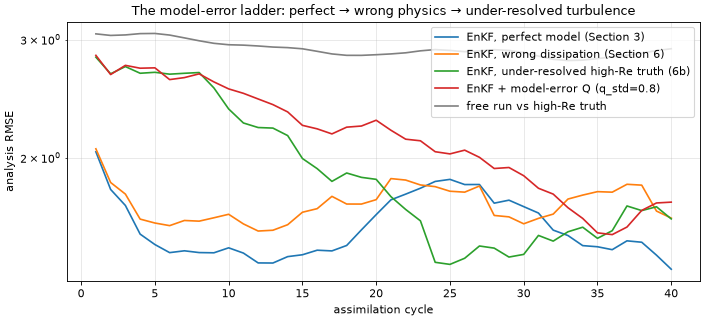

final RMSE  enkf-hires: 1.622   +Q: 1.718   free: 2.908   |   ratio vs perfect-model EnKF: 1.2x


In [13]:
from kalman.apps.weather import turbulence_truth
from kalman.apps import NS2D

hires = NS2D(n=128, nu=1/300., kf=4, chi=2.0, dt=0.005, seed=11)
w = hires.advance(hires.random_ic(), 2500)                  # independent spin-up
frames = []
for _ in range(N_CYCLES):
    w = hires.advance(w, 30)
    frames.append(w.copy())
traj_hr = turbulence_truth(np.asarray(frames), model)       # 128² -> block-mean -> 64², rescaled

osse4 = TwinExperiment(model, n_cycles=N_CYCLES, n_members=N_MEMBERS,
                       seed_obs=999, seed_setup=123, obs_periods=(2, 6),
                       truth_trajectory=traj_hr)
osse4.add_method("enkf-hires", inflation=1.12)
osse4.add_method("enkf-hires+Q", inflation=1.05, q_std=0.8)   # additive model-error noise
osse4.add_free_run("free")
hist4 = osse4.run(every=10)
ratio4 = osse4.skill(reference=hist["enkf"])["enkf-hires"]

fig, ax = plt.subplots(figsize=(9, 4.2))
cyc = np.arange(1, N_CYCLES + 1)
ax.semilogy(cyc, hist["enkf"]["rmse_a"], label="EnKF, perfect model (Section 3)")
ax.semilogy(cyc, hist3["enkf-imperfect"]["rmse_a"], label="EnKF, wrong dissipation (Section 6)")
ax.semilogy(cyc, hist4["enkf-hires"]["rmse_a"], label="EnKF, under-resolved high-Re truth (6b)")
ax.semilogy(cyc, hist4["enkf-hires+Q"]["rmse_a"], label="EnKF + model-error Q (q_std=0.8)")
ax.semilogy(cyc, hist4["free"]["rmse_a"], color="gray", label="free run vs high-Re truth")
ax.set_xlabel("assimilation cycle"); ax.set_ylabel("analysis RMSE")
ax.legend(); ax.grid(alpha=0.3, which="both")
ax.set_title("The model-error ladder: perfect → wrong physics → under-resolved turbulence")
plt.tight_layout(); plt.show()
print(f"final RMSE  enkf-hires: {hist4['enkf-hires']['rmse_a'][-1]:.3f}   "
      f"+Q: {hist4['enkf-hires+Q']['rmse_a'][-1]:.3f}   "
      f"free: {hist4['free']['rmse_a'][-1]:.3f}   |   ratio vs perfect-model EnKF: {ratio4[-1]:.1f}x")

## Step 7 — Negative Results Worth Keeping

The prototype study behind this notebook spent most of its effort on approaches that *did not* work. They are recorded here because each one shaped the API you just used.

**Linear latent-space DA has a hard floor. This is why there is no `latent=` option.** This applies to POD (proper orthogonal decomposition) and DMD (dynamic mode decomposition), the two standard linear latent-space methods. A 50-mode POD basis captured 99.5% of the *time-averaged energy* of this flow. Yet instantaneous turbulent snapshots kept a root-mean-square (RMS) component of about 0.95 (against a field standard deviation of about 2) that stayed orthogonal to even the full snapshot span. Energy capture is a second-moment, time-averaged statistic. It says nothing about representing *individual* states. As a result, an EnKF whose analysis lives in any linear latent space stalled at RMSE ≈ 1.2, regardless of latent dimension (15 to 150 tested) or tuning. This was barely better than no assimilation at all.

Two extra traps apply here:

- Inflating in *full* space pumps up the unobservable orthogonal residual, and can end up **worse than no assimilation**.
- Even latent-only inflation needs the orthogonal residual explicitly damped, or it grows without bound.

If a latent space is ever needed, for example for learned observation operators or genuine dimension reduction, it must be a **nonlinear autoencoder**. Validate it on instantaneous-snapshot reconstruction error, not on energy capture, before using it in a filter.

**Surrogate forecasts diverge under cycling far more easily than open-loop tests suggest.** The prototype's one-step-trained network exploded, with RMSE rising from 3.4 to 76. Step 4 shows that even a rollout-trained network, at this toy training budget, still spirals. The cause is that *analysis increments push states off the training manifold*. This is a distributional failure that no open-loop metric can see. The rollout loss, the `rollout_rmse` gate, and `ReanchoredForecast` all exist because of this failure mode.

**Shared RNG streams silently invalidate comparisons.** An early version of the prototype drew all its random numbers from one global stream. Adding a second method to the loop consumed extra random draws, and changed the observation noise every other method saw. Method A's "own" results moved from RMSE 0.19 to 1.6, even though method A's code stayed untouched. The framework now enforces a strict discipline: one shared stream for the physical observation realization (`TwinExperiment.rng_obs`, so every method sees the same measurements), and one **engine-owned** stream per method for perturbed-observation draws (`EnsembleKalmanEngine(seed=...)`). The test `test_rng_discipline_invariance` locks this behavior in permanently.


## Summary

| | |
|---|---|
| **Estimate fields, not vectors** | `EnsembleKalmanFilter` uses the sample covariance from $N\ll n$ members. It never forms a dense $P$ matrix. Perturbed observations keep the ensemble spread honest. |
| **Make $N=16$ work in $n=4096$** | Gaspari–Cohn localization (`model.localization()`) removes spurious long-range sample covariances. Multiplicative inflation compensates for finite-$N$ overconfidence. |
| **Validate like the weather services** | `TwinExperiment` runs an OSSE: known truth, synthetic observations, a free-run control, RMSE, and spread-vs-error calibration. |
| **Insert AI where it pays** | Replace the forecast step (`model.surrogate` / `add_method(forecast=...)`). Train with a **rollout loss**. Gate on **open-loop rollout error**. Give the surrogate branch its **own inflation**. **Re-anchor** with the true solver until the surrogate earns full trust. |
| **Replay any truth** | `TwinExperiment(truth_trajectory=...)` runs imperfect-model twins and real-data (ERA5) experiments in the same harness. `kalman.apps.weather` turns u/v reanalysis data into a model-units trajectory. Judge results by `skill()` ratios. |
| **Don't** | Analyze in a linear latent space (it hits a representation floor). Trust one-step training under cycling. Share RNG streams across compared methods. Use a bootstrap particle filter on fields. |

The pattern to carry to a real application, such as regional weather, typhoon tracks, or plasma profiles: keep the full-space, localized EnKF as the analysis backbone. Treat every learned component as a *forecast* or *observation* plug-in, behind the same model contract. Make each component earn its place inside this harness first.
